# HousePrice AI — Phase 1: Exploratory Data Analysis (EDA)

## 1. Objective
The goal of this notebook is to perform comprehensive Exploratory Data Analysis on the **Kaggle Ames Housing dataset** (*House Prices: Advanced Regression Techniques*).

Key questions addressed in this analysis:
1. What is the shape, structure, and feature types of the dataset?
2. How is the target variable (`SalePrice`) distributed?
3. Which numerical features exhibit strong correlations with property prices?
4. What missing values, duplicates, and outliers exist, and how should they inform our preprocessing strategy?

---

In [21]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Add src to Python path
sys.path.append(os.path.abspath('..'))

from src.data_loader import load_dataset, display_basic_info, get_summary_statistics, check_missing_values, check_duplicates
from src.visualization import (plot_sale_price_distribution, plot_feature_vs_target, 
                               plot_quality_vs_price, plot_correlation_heatmap, plot_box_plot)

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

## 2. Dataset Loading & Verification
We expect the official competition training CSV at `../data/raw/train.csv`.
If it is missing, we check for available data and provide download instructions.

In [22]:
data_path = '../data/raw/train.csv'

df = load_dataset(data_path)

print(f'Dataset successfully loaded: {df.shape[0]} rows, {df.shape[1]} columns.')

[INFO] Dataset loaded successfully from: ../data/raw/train.csv
   Shape: 1460 rows x 81 columns
Dataset successfully loaded: 1460 rows, 81 columns.


## 3. Dataset Inspection & Structural Overview

In [23]:
display_basic_info(df)

DATASET BASIC INFORMATION

Shape: 1460 rows x 81 columns

Columns (81):
     1. Id (int64)
     2. MSSubClass (int64)
     3. MSZoning (object)
     4. LotFrontage (float64)
     5. LotArea (int64)
     6. Street (object)
     7. Alley (object)
     8. LotShape (object)
     9. LandContour (object)
    10. Utilities (object)
    11. LotConfig (object)
    12. LandSlope (object)
    13. Neighborhood (object)
    14. Condition1 (object)
    15. Condition2 (object)
    16. BldgType (object)
    17. HouseStyle (object)
    18. OverallQual (int64)
    19. OverallCond (int64)
    20. YearBuilt (int64)
    21. YearRemodAdd (int64)
    22. RoofStyle (object)
    23. RoofMatl (object)
    24. Exterior1st (object)
    25. Exterior2nd (object)
    26. MasVnrType (object)
    27. MasVnrArea (float64)
    28. ExterQual (object)
    29. ExterCond (object)
    30. Foundation (object)
    31. BsmtQual (object)
    32. BsmtCond (object)
    33. BsmtExposure (object)
    34. BsmtFinType1 (object)
    35

## 4. Missing Values & Duplicate Inspection

In [24]:
missing_df = check_missing_values(df)
n_duplicates = check_duplicates(df)

MISSING VALUES REPORT
[WARNING] 19 columns have missing values:

              Missing Count  Missing Percentage
PoolQC                 1453               99.52
MiscFeature            1406               96.30
Alley                  1369               93.77
Fence                  1179               80.75
MasVnrType              872               59.73
FireplaceQu             690               47.26
LotFrontage             259               17.74
GarageType               81                5.55
GarageYrBlt              81                5.55
GarageFinish             81                5.55
GarageQual               81                5.55
GarageCond               81                5.55
BsmtExposure             38                2.60
BsmtFinType2             38                2.60
BsmtQual                 37                2.53
BsmtCond                 37                2.53
BsmtFinType1             37                2.53
MasVnrArea                8                0.55
Electrical             

## 5. Target Variable Analysis: Sale Price

The distribution of housing prices often exhibits positive (right) skewness because a small number of luxury properties sell for disproportionately high amounts.

Target column: SalePrice
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


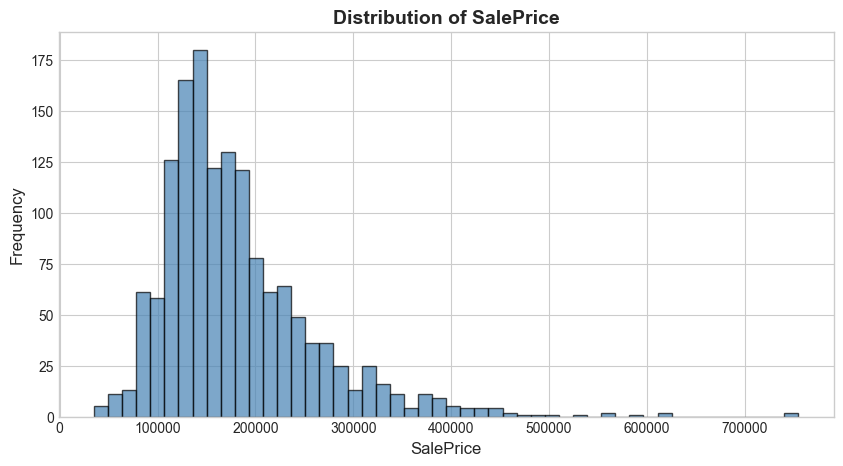

[SAVED] ../outputs/eda/sale_price_distribution.png


In [25]:
target_col = 'SalePrice' if 'SalePrice' in df.columns else ('Price' if 'Price' in df.columns else df.columns[-1])
print(f'Target column: {target_col}')
print(df[target_col].describe())

# Plot distribution
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df[target_col], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
ax.set_title(f'Distribution of {target_col}', fontsize=14, fontweight='bold')
ax.set_xlabel(target_col, fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
plt.show()

# Save plot to outputs
plot_sale_price_distribution(df[target_col], save_path='../outputs/eda/sale_price_distribution.png')

## 6. Selected Feature Distributions & Relationships

We focus on the six primary baseline features:
- `GrLivArea`: Above-grade living area in square feet
- `OverallQual`: Overall material and finish quality rating (1-10)
- `YearBuilt`: Original construction date
- `BedroomAbvGr`: Bedrooms above grade
- `FullBath`: Full bathrooms above grade
- `GarageCars`: Size of garage in car capacity

Available baseline features: ['GrLivArea', 'OverallQual', 'YearBuilt', 'BedroomAbvGr', 'FullBath', 'GarageCars']
[SAVED] ../outputs/eda/grlivarea_vs_price.png


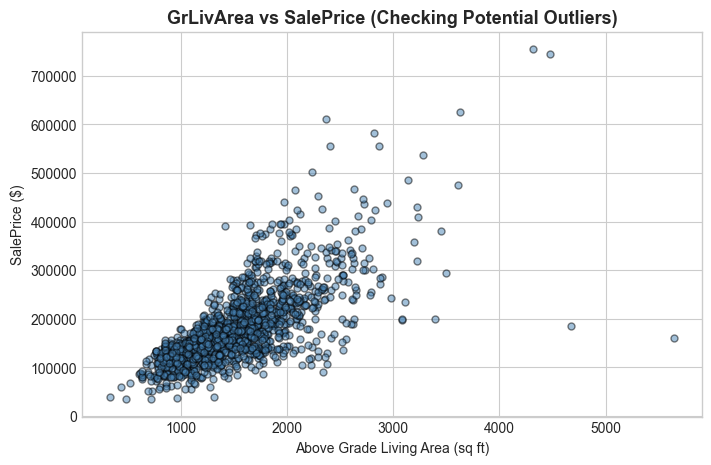

[SAVED] ../outputs/eda/quality_vs_price.png


In [26]:
baseline_features = ['GrLivArea', 'OverallQual', 'YearBuilt', 'BedroomAbvGr', 'FullBath', 'GarageCars']
available_features = [f for f in baseline_features if f in df.columns]
print(f'Available baseline features: {available_features}')

if 'GrLivArea' in df.columns and target_col in df.columns:
    plot_feature_vs_target(df['GrLivArea'], df[target_col], 'GrLivArea', save_path='../outputs/eda/grlivarea_vs_price.png')
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(df['GrLivArea'], df[target_col], alpha=0.5, color='steelblue', edgecolors='k', s=25)
    ax.set_title('GrLivArea vs SalePrice (Checking Potential Outliers)', fontsize=13, fontweight='bold')
    ax.set_xlabel('Above Grade Living Area (sq ft)')
    ax.set_ylabel('SalePrice ($)')
    plt.show()

if 'OverallQual' in df.columns and target_col in df.columns:
    plot_quality_vs_price(df, save_path='../outputs/eda/quality_vs_price.png')

## 7. Correlation Heatmap
Understanding linear correlations between continuous features and `SalePrice` validates whether linear regression is a suitable model.

In [27]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
selected_for_corr = [c for c in baseline_features + [target_col] if c in numeric_cols]

if len(selected_for_corr) > 1:
    plot_correlation_heatmap(df, selected_for_corr, save_path='../outputs/eda/correlation_heatmap.png')
    corr_matrix = df[selected_for_corr].corr()
    display(corr_matrix)

[SAVED] ../outputs/eda/correlation_heatmap.png


,GrLivArea,OverallQual,YearBuilt,BedroomAbvGr,FullBath,GarageCars,SalePrice
GrLivArea,1.000000,0.593007,0.199010,0.521270,0.630012,0.467247,0.708624
OverallQual,0.593007,1.000000,0.572323,0.101676,0.550600,0.600671,0.790982
YearBuilt,0.199010,0.572323,1.000000,-0.070651,0.468271,0.537850,0.522897
BedroomAbvGr,0.521270,0.101676,-0.070651,1.000000,0.363252,0.086106,0.168213
FullBath,0.630012,0.550600,0.468271,0.363252,1.000000,0.469672,0.560664
GarageCars,0.467247,0.600671,0.537850,0.086106,0.469672,1.000000,0.640409
SalePrice,0.708624,0.790982,0.522897,0.168213,0.560664,0.640409,1.000000


## 8. Summary of EDA Insights
1. **Strong Linear Predictors:** `OverallQual` and `GrLivArea` show the highest correlation with `SalePrice`.
2. **Target Skewness:** Housing prices are right-skewed; a log transformation $\log(1 + \text{SalePrice})$ will be explored in later experiments.
3. **Missing Value Strategy:** Missing numeric feature values are safely imputed using median values computed strictly from the training split.
4. **Outlier Awareness:** Notice properties with unusually large living area but low price; we preserve legitimate data points during baseline training.